In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("insurance (1).csv")

df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# check duplicates

df.duplicated().sum()

1

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.duplicated().sum()

0

In [10]:
# check null values 

df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [12]:
# checking data type

df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [13]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [14]:
# dropping region column
df.drop(columns=['region'],inplace=True)

In [15]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
charges     float64
dtype: object

In [16]:
df['sex'].unique()

array(['female', 'male'], dtype=object)

In [17]:
df['sex'] = df['sex'].map({'female':0,'male':1})

df.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker       object
charges     float64
dtype: object

In [18]:
df['smoker'].unique()

array(['yes', 'no'], dtype=object)

In [19]:
df['smoker'] = df['smoker'].map({'yes':1,'no':0})

df.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
charges     float64
dtype: object

In [21]:
# to identify only relevant columns

x = df.corr()
x

,age,sex,bmi,children,smoker,charges
age,1.000000,-0.019814,0.109344,0.041536,-0.025587,0.298308
sex,-0.019814,1.000000,0.046397,0.017848,0.076596,0.058044
bmi,0.109344,0.046397,1.000000,0.012755,0.003746,0.198401
children,0.041536,0.017848,0.012755,1.000000,0.007331,0.067389
smoker,-0.025587,0.076596,0.003746,0.007331,1.000000,0.787234
charges,0.298308,0.058044,0.198401,0.067389,0.787234,1.000000


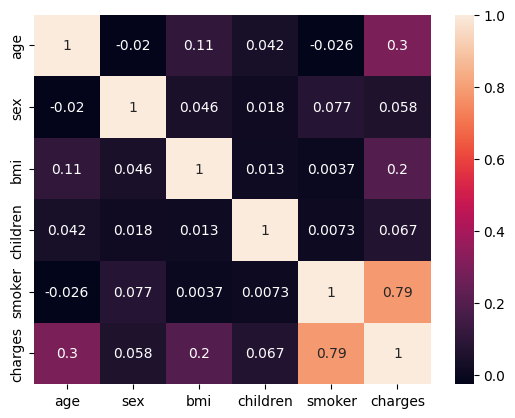

In [24]:
# display correlation on map

sns.heatmap(x,annot=True)

plt.show()

In [25]:
# identify target and features

Y = df['charges']   # target

X = df.drop(columns=['charges'])  # feature

In [28]:
X

,age,sex,bmi,children,smoker
0,19,0,27.900,0,1
1,18,1,33.770,1,0
2,28,1,33.000,3,0
3,33,1,22.705,0,0
4,32,1,28.880,0,0
...,...,...,...,...,...
1333,50,1,30.970,3,0
1334,18,0,31.920,0,0
1335,18,0,36.850,0,0
1336,21,0,25.800,0,0


In [30]:
# importing ML library

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import math as m

In [31]:
x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [32]:
len(x_train)

1069

In [33]:
len(x_test)

268

In [35]:
# model training

model = LinearRegression()

model.fit(x_train,y_train)

LinearRegression()

In [37]:
# prediction
y_pred = model.predict(x_test)

In [43]:
X.head(2)

,age,sex,bmi,children,smoker
0,19,0,27.90,0,1
1,18,1,33.77,1,0


In [ ]:
# single user charges prediction

In [44]:
model.predict([[19,0,27.9,0,1]])

C:\Users\uwais\anaconda3\Lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([25089.26781169])

In [38]:
# Model evaluation

mean_absolute_error(y_test,y_pred)

4198.1118004745995

In [40]:
mse = mean_squared_error(y_test,y_pred)

mse

35901914.11461982

In [41]:
rmse = m.sqrt(mse)

rmse

5991.820601004324

In [42]:
r2_score(y_test,y_pred)

0.8046218811772661